In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression 
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [2]:
df = pd.read_csv('housing.csv')

In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.shape

(20640, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [6]:
df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [7]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [8]:
# VISUALIZATION

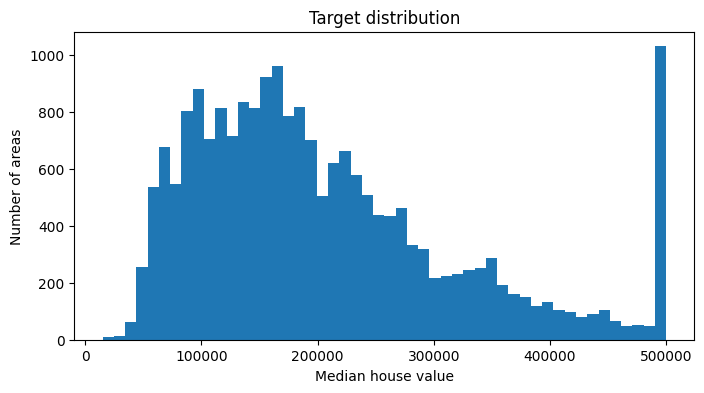

In [14]:
plt.figure(figsize=(8, 4))
plt.hist(df['median_house_value'], bins=50)
plt.xlabel('Median house value')
plt.ylabel('Number of areas')
plt.title('Target distribution')
plt.show()

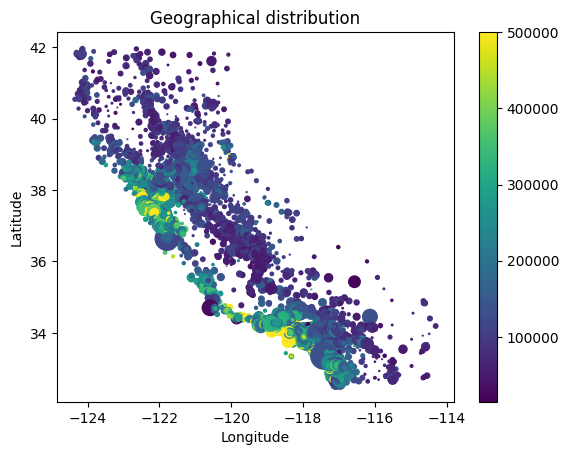

In [20]:
scatter = plt.scatter(df['longitude'], df['latitude'], s=df['population'] / 100, c=df['median_house_value'])
plt.colorbar(scatter)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographical distribution')
plt.show()

In [21]:
corr = df.drop(columns='ocean_proximity').corr()

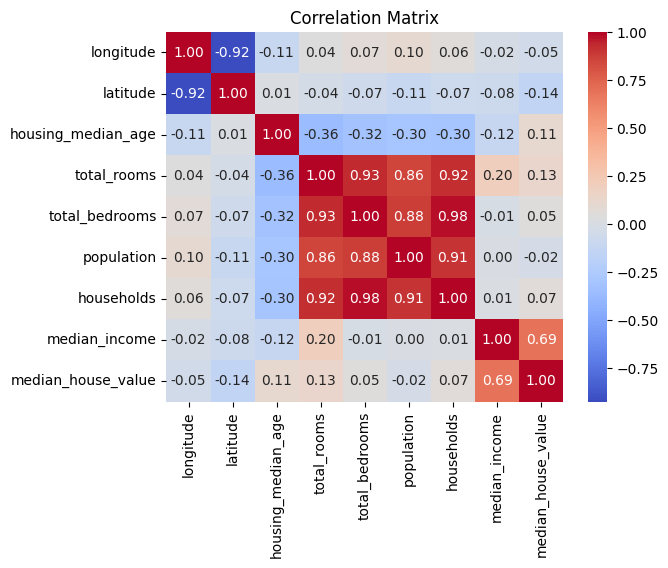

In [28]:
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlation Matrix')
plt.show()

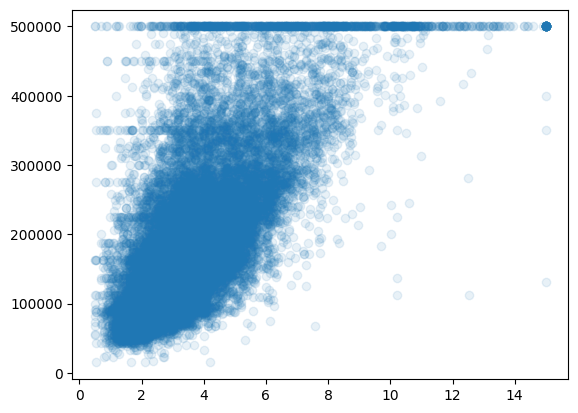

In [32]:
plt.scatter(df['median_income'], df['median_house_value'], alpha=0.1)
plt.show()

In [33]:
# Fix issue with bedrooms

In [36]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [37]:
df.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [38]:
X = df.drop(columns='median_house_value')

In [40]:
X = pd.get_dummies(X, columns=['ocean_proximity'], dtype=int)

In [42]:
y = df['median_house_value']

In [44]:
trainX,testX, trainY, testY = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
model = LinearRegression()

In [46]:
model.fit(trainX, trainY)

LinearRegression()

In [47]:
prediction = model.predict(testX)

In [48]:
mean_absolute_error(testY, prediction)

50670.73824097197

In [51]:
np.sqrt(mean_squared_error(testY, prediction))

70060.52184473505

In [52]:
r2_score(testY, prediction)

0.6254240620553622

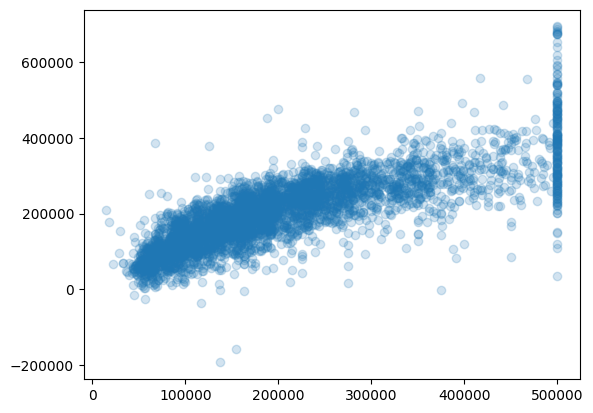

In [54]:
plt.scatter(testY, prediction, alpha=0.2)
plt.show()

In [56]:
df.shape

(20640, 10)

In [57]:
df2 = df[df.median_house_value < 500000]

In [58]:
df2.shape

(19648, 10)

In [59]:
X = df2.drop(columns='median_house_value')

In [60]:
X = pd.get_dummies(X, columns=['ocean_proximity'], dtype=int)

In [62]:
y = df2['median_house_value']

In [63]:
trainX,testX, trainY, testY = train_test_split(X, y, test_size=0.2, random_state=42)

In [64]:
model = LinearRegression()

In [65]:
model.fit(trainX, trainY)

LinearRegression()

In [66]:
prediction = model.predict(testX)

In [67]:
mean_absolute_error(testY, prediction)

45345.55449945409

In [68]:
np.sqrt(mean_squared_error(testY, prediction))

60927.24961044405

In [69]:
r2_score(testY, prediction)

0.6128066483029366

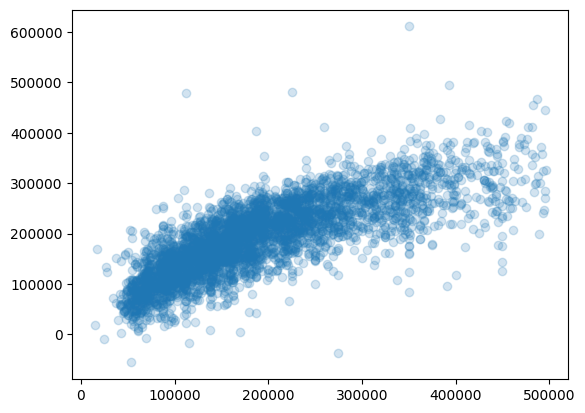

In [70]:
plt.scatter(testY, prediction, alpha=0.2)
plt.show()

In [73]:
forest = RandomForestRegressor()

In [74]:
forest.fit(trainX, trainY)

RandomForestRegressor()

In [75]:
prediction = forest.predict(testX)

In [76]:
mean_absolute_error(testY, prediction)

30265.3677302799

In [77]:
np.sqrt(mean_squared_error(testY, prediction))

45359.932548002886

In [78]:
r2_score(testY, prediction)

0.7853902025478383